# Beginner challenge: portfolio selection as augmented Max-Cut QAOA

**Track:** Choosing Wisely — optimization under constraints.
**Level:** Beginner.
**Solver:** QAOA on a noiseless statevector simulator.

This notebook turns a budget-constrained portfolio into an Ising model, then into a weighted Max-Cut graph with one fixed reference node. The circuit is built from that graph. There is one encoding and one circuit. Brute force on the same $2^6$ bitstrings is the exact benchmark.

This is a 7-qubit noiseless simulation (6 assets + 1 reference). It is not a claim of quantum advantage: every feasible portfolio can be scored classically in a few lines.


## 1. Portfolio data

We have $n=6$ assets and must hold **exactly** $K=3$ of them. $x_i=1$ means asset $i$ is included. The quantity to **maximize** is the mean–variance score

$$
f(x)=\sum_{i=1}^{n}\mu_i x_i-q\sum_{i,j}\sigma_{ij}x_i x_j,
\qquad
\sum_i x_i=K,
\qquad
x_i\in\{0,1\}.
$$

$\mu_i$ is the expected return of asset $i$. $\sigma_{ij}$ is the covariance. The sum over $i,j$ includes $i=j$ and both orders $(i,j)$ and $(j,i)$. $q>0$ is a risk aversion we choose: larger $q$ punishes variance more.

The covariance is a one-factor model, positive semidefinite by construction:

$$
\sigma_{ij}=v_{\mathrm{mkt}}\,\beta_i\beta_j+\delta_{ij}\omega_i^2.
$$

Asset 2 has a high expected return and a high market exposure. Asset 4 has a low return and a low exposure. With a large enough $q$, the best portfolio is not the three assets with the largest $\mu_i$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product, combinations

from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from scipy.optimize import minimize

np.set_printoptions(precision=4, suppress=True)

n = 6
K = 3
q = 2.0

mu = np.array([0.10, 0.16, 0.22, 0.11, 0.07, 0.19])
beta = np.array([0.8, 1.0, 1.4, 0.7, 0.5, 1.3])
market_var = 0.02
idio_vol = np.array([0.04, 0.05, 0.12, 0.04, 0.03, 0.10])
sigma = market_var * np.outer(beta, beta) + np.diag(idio_vol ** 2)

def portfolio_value(x, risk_aversion=None):
    """Mean-variance score f(x). This is the objective we report at the end."""
    if risk_aversion is None:
        risk_aversion = q
    x = np.asarray(x, dtype=float)
    return float(mu @ x - risk_aversion * (x @ sigma @ x))

print("n =", n, " K =", K, " q =", q)
print("smallest eigenvalue of sigma:", np.linalg.eigvalsh(sigma).min())
print("expected returns mu:")
print(mu)
print("covariance sigma:")
print(sigma)


n = 6  K = 3  q = 2.0
smallest eigenvalue of sigma: 0.0009866070636357761
expected returns mu:
[0.1  0.16 0.22 0.11 0.07 0.19]
covariance sigma:
[[0.0144 0.016  0.0224 0.0112 0.008  0.0208]
 [0.016  0.0225 0.028  0.014  0.01   0.026 ]
 [0.0224 0.028  0.0536 0.0196 0.014  0.0364]
 [0.0112 0.014  0.0196 0.0114 0.007  0.0182]
 [0.008  0.01   0.014  0.007  0.0059 0.013 ]
 [0.0208 0.026  0.0364 0.0182 0.013  0.0438]]


### How to read this

`portfolio_value` is equation $f(x)$ written as a matrix product. `mu @ x` is the return term. `x @ sigma @ x` is $\sum_{i,j}\sigma_{ij}x_i x_j$. The smallest eigenvalue is positive, so $\sigma$ is a valid covariance and the risk term is never negative for a nonzero portfolio.


## 2. Brute-force classical optimum

Only portfolios with exactly $K$ ones are legal. There are

$$
\binom{n}{K}=\binom{6}{3}=20
$$

of them, out of $2^6=64$ binary vectors. Scoring all 20 gives the exact maximum $f^\star$ and an optimal portfolio $x^\star$. Later, the QAOA approximation ratio is a sampled feasible score divided by this $f^\star$.

The same loop with $q=0$ ranks portfolios by return only. Comparing the two answers shows what the risk term does.


In [2]:
def feasible_portfolios(risk_aversion):
    rows = []
    for chosen in combinations(range(n), K):
        x = np.zeros(n)
        x[list(chosen)] = 1.0
        rows.append((portfolio_value(x, risk_aversion), x))
    rows.sort(key=lambda row: row[0], reverse=True)
    return rows

ranked = feasible_portfolios(q)
f_star, x_star = ranked[0]
return_only = feasible_portfolios(0.0)

print(f"Feasible portfolios scored: {len(ranked)}")
print("Best portfolios at q = 2 (score, assets held):")
for value, x in ranked[:5]:
    print(f"  f = {value: .4f}   assets {np.flatnonzero(x).tolist()}")

print("Best portfolio if risk is ignored (q = 0):")
print(f"  return = {return_only[0][0]: .4f}   assets {np.flatnonzero(return_only[0][1]).tolist()}")
print("That same high-return portfolio, scored at q = 2:")
print(f"  f = {portfolio_value(return_only[0][1]): .4f}")
print("Brute-force optimum x*: assets", np.flatnonzero(x_star).tolist(), "  f* =", round(f_star, 6))
assert abs(x_star.sum() - K) < 1e-12
assert f_star > 0


Feasible portfolios scored: 20
Best portfolios at q = 2 (score, assets held):
  f =  0.1364   assets [1, 3, 4]
  f =  0.1118   assets [0, 3, 4]
  f =  0.1086   assets [0, 1, 3]
  f =  0.1084   assets [0, 1, 4]
  f =  0.0958   assets [2, 3, 4]
Best portfolio if risk is ignored (q = 0):
  return =  0.5700   assets [1, 2, 5]
That same high-return portfolio, scored at q = 2:
  f = -0.0314
Brute-force optimum x*: assets [1, 3, 4]   f* = 0.1364


### How to read this

Every printed portfolio holds 3 assets, so the cardinality constraint is satisfied by construction. $f^\star$ is the number the quantum samples will be judged against.

The $q=0$ winner is the three largest expected returns. At $q=2$ that portfolio has a **negative** score: its variance costs more than its extra return. The brute-force optimum is a quieter set of assets. QAOA has to find that set, not merely the largest $\mu_i$.


## 3. QUBO-to-Ising conversion

QAOA minimizes an energy. Portfolio selection maximizes $f$ and has a constraint, so we minimize the penalized cost

$$
C(x)=-f(x)+\lambda\left(\sum_i x_i-K\right)^2.
$$

$\lambda>0$ is the penalty strength. A portfolio that holds the wrong number of assets pays $\lambda$ times the squared violation. Expanding $f$ and the square, and using $x_i^2=x_i$, gives a quadratic polynomial

$$
C(x)=c_0+\sum_i a_i x_i+\sum_{i<j}b_{ij}x_i x_j.
$$

The coefficients are

$$
\begin{aligned}
a_i &= -\mu_i+q\sigma_{ii}+\lambda(1-2K),\\
b_{ij} &= 2q\sigma_{ij}+2\lambda \qquad (i<j),\\
c_0 &= \lambda K^2.
\end{aligned}
$$

The $2$ in $b_{ij}$ appears because $\sum_{i,j}$ counts each unordered pair twice, and because $(\sum_i x_i)^2$ contains $2x_i x_j$.

Substitute the spin variable used by the Ising model,

$$
x_i=\frac{1-Z_i}{2},\qquad Z_i\in\{+1,-1\}.
$$

Then $x_i=1$ is the spin $Z_i=-1$, and $x_i=0$ is $Z_i=+1$. The product is

$$
x_i x_j=\frac{1-Z_i-Z_j+Z_i Z_j}{4}.
$$

Collecting constants, single-$Z$ terms, and $ZZ$ terms produces

$$
H_C=c+\sum_i h_i Z_i+\sum_{i<j}J_{ij}Z_i Z_j,
$$

with

$$
\begin{aligned}
h_i &= -\frac{a_i}{2}-\frac{1}{4}\sum_{j\neq i}b_{ij},\\
J_{ij} &= \frac{b_{ij}}{4},\\
c &= c_0+\frac12\sum_i a_i+\frac14\sum_{i<j}b_{ij}.
\end{aligned}
$$

On a computational basis state, $\langle x|H_C|x\rangle=C(x)$, including the constant. The constant does not change which portfolio is best. It is kept so the quantum expectation value can be compared directly with $C(x)$.

$\lambda$ has to be large enough that no illegal portfolio has a lower cost than $x^\star$. For every infeasible $x$,

$$
\lambda \ge \frac{f(x)-f^\star}{(\sum_i x_i-K)^2}
$$

whenever $f(x)>f^\star$. The maximum of the right-hand side is the smallest such $\lambda$, called $\lambda_{\min}$ below. We then pick a fixed $\lambda$ safely above it for the worked example. A weak penalty is studied later, on purpose.


In [3]:
def cost_direct(x, lam):
    """C(x) = -f(x) + lambda * (sum x - K)^2, evaluated directly."""
    x = np.asarray(x, dtype=float)
    return -portfolio_value(x) + lam * (np.sum(x) - K) ** 2

lambda_min = 0.0
for bits in product([0, 1], repeat=n):
    x = np.array(bits, dtype=float)
    violation = (np.sum(x) - K) ** 2
    if violation == 0:
        continue
    lambda_min = max(lambda_min, (portfolio_value(x) - f_star) / violation)

LAM = 0.2
print(f"lambda_min = {lambda_min:.6f}")
print(f"worked example uses lambda = {LAM}")

def ising_from_portfolio(lam):
    """Return QUBO coefficients (a, b, c0) and Ising coefficients (h, J, c)."""
    a = -mu + q * np.diag(sigma) + lam * (1 - 2 * K)
    b = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            b[i, j] = b[j, i] = 2 * q * sigma[i, j] + 2 * lam
    c0 = lam * K ** 2

    h = np.zeros(n)
    J = np.zeros((n, n))
    for i in range(n):
        pair_sum = np.sum(b[i]) - b[i, i]
        h[i] = -0.5 * a[i] - 0.25 * pair_sum
        for j in range(i + 1, n):
            J[i, j] = 0.25 * b[i, j]
    c = c0 + 0.5 * np.sum(a) + 0.25 * np.sum(b[np.triu_indices(n, k=1)])
    return a, b, c0, h, J, c

a, b, c0, h, J, c = ising_from_portfolio(LAM)

max_gap = 0.0
ground_energy = np.inf
ground_state = None
for bits in product([0, 1], repeat=n):
    x = np.array(bits, dtype=float)
    direct = cost_direct(x, LAM)
    polynomial = c0 + float(a @ x)
    for i in range(n):
        for j in range(i + 1, n):
            polynomial += b[i, j] * x[i] * x[j]
    z = 1 - 2 * x
    ising = c + float(h @ z)
    for i in range(n):
        for j in range(i + 1, n):
            ising += J[i, j] * z[i] * z[j]
    max_gap = max(max_gap, abs(direct - polynomial), abs(direct - ising))
    if direct < ground_energy:
        ground_energy = direct
        ground_state = x.copy()

print("max |C - QUBO| and |C - Ising| over all 64 bitstrings:", max_gap)
print("ground state of C: assets", np.flatnonzero(ground_state).tolist(),
      " count =", int(ground_state.sum()),
      " C =", round(ground_energy, 6))
print("linear fields h:")
print(h)
print("ZZ couplings J (upper triangle):")
print(np.triu(J, k=1))
assert max_gap < 1e-8
assert int(ground_state.sum()) == K
assert np.array_equal(ground_state, x_star)


lambda_min = 0.009800
worked example uses lambda = 0.2


max |C - QUBO| and |C - Ising| over all 64 bitstrings: 8.881784197001252e-16
ground state of C: assets [1, 3, 4]  count = 3  C = -0.1364
linear fields h:
[-0.0428 -0.0365 -0.064  -0.0264 -0.0229 -0.0632]
ZZ couplings J (upper triangle):
[[0.     0.116  0.1224 0.1112 0.108  0.1208]
 [0.     0.     0.128  0.114  0.11   0.126 ]
 [0.     0.     0.     0.1196 0.114  0.1364]
 [0.     0.     0.     0.     0.107  0.1182]
 [0.     0.     0.     0.     0.     0.113 ]
 [0.     0.     0.     0.     0.     0.    ]]


### How to read this

`ising_from_portfolio` is the algebra above, not a second objective. The loop then evaluates three numbers on every bitstring: the definition of $C(x)$, the polynomial with coefficients $a,b,c_0$, and the Ising expression with $Z_i=1-2x_i$. They agree to rounding error. That is the check that the factors $\tfrac12$ and $\tfrac14$ are in the right places.

At $\lambda=0.2>\lambda_{\min}$, the lowest value of $C$ is the brute-force portfolio $x^\star$, and that state holds exactly 3 assets. The penalty has not changed the constrained optimum. It has only made every illegal bitstring more expensive.

$h_i$ is not $\mu_i$. Each local field also absorbs pieces of the pair terms $b_{ij}$, because $x_i x_j$ contains single-$Z$ pieces after the substitution.


## 4. Augmented Max-Cut graph

The Ising cost still has single-qubit fields $h_i Z_i$. Max-Cut Hamiltonians are written only with pair interactions. The standard weighted Max-Cut cost, up to an additive constant, is

$$
\sum_{(u,v)\in E}\frac{w_{uv}}{2}Z_u Z_v.
$$

A textbook unweighted edge has $w_{uv}=1$, which is why the Max-Cut tutorial uses $\tfrac12 Z_i Z_j$ on each edge.

Add one reference node $r$ and **fix its spin at $Z_r=+1$**. Then

$$
h_i Z_i = h_i Z_i Z_r.
$$

Matching coefficients with the Max-Cut form gives the edge weights

$$
w_{ij}=2J_{ij},\qquad w_{ir}=2h_i.
$$

Indeed $\tfrac{w_{ij}}{2}=J_{ij}$ and $\tfrac{w_{ir}}{2}Z_i Z_r=h_i Z_i$ once $Z_r=+1$. Energy **differences** between portfolios are unchanged. This is the augmented graph: the original 6 vertices, plus $r$, with an edge for every nonzero coupling.

This is a **generalised** weighted Max-Cut, not ordinary Max-Cut.

- Ordinary Max-Cut asks for a heaviest cut and uses **non-negative** weights. Cutting an edge is always a reward.
- Here $w_{ir}=2h_i$ can be negative, and a negative $J_{ij}$ would make $w_{ij}$ negative too. A negative weight lowers the energy when the two spins are **equal** ($Z_u Z_v=+1$), which means those two vertices prefer to sit in the same subset.
- Positive $w_{ij}$ prefers opposite spins. In this problem the pair weight is $w_{ij}=q\sigma_{ij}+\lambda$. Both $\sigma_{ij}$ (for assets that move together) and $\lambda$ are non-negative, so asset–asset edges are non-negative: the cost prefers not to hold both endpoints. The reference edges carry the local fields and are where the signs come from.

The graph is complete on the asset vertices because every pair has a risk term or a penalty term. Sparsity is not the point of this encoding. The point is that every term in $H_C$ is a two-body $ZZ$ on a graph with one pinned vertex.


max |Max-Cut energy - C(x)| with Z_r = +1: 8.881784197001252e-16
edge weights range from -0.1280 to  0.2728
negative edges: 6   positive edges: 15


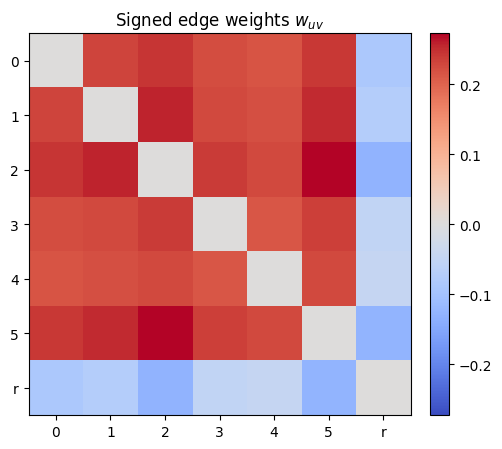

In [4]:
W = np.zeros((n + 1, n + 1))
for i in range(n):
    for j in range(i + 1, n):
        W[i, j] = W[j, i] = 2 * J[i, j]
    W[i, n] = W[n, i] = 2 * h[i]

max_cut_gap = 0.0
for bits in product([0, 1], repeat=n):
    x = np.array(bits, dtype=float)
    z = np.append(1 - 2 * x, 1.0)  # last entry is Z_r = +1
    energy = c
    for i in range(n + 1):
        for j in range(i + 1, n + 1):
            energy += 0.5 * W[i, j] * z[i] * z[j]
    max_cut_gap = max(max_cut_gap, abs(energy - cost_direct(x, LAM)))

off = W[np.triu_indices(n + 1, k=1)]
print("max |Max-Cut energy - C(x)| with Z_r = +1:", max_cut_gap)
print(f"edge weights range from {off.min(): .4f} to {off.max(): .4f}")
print(f"negative edges: {np.count_nonzero(off < 0)}   positive edges: {np.count_nonzero(off > 0)}")
assert max_cut_gap < 1e-8
assert np.any(off < 0) and np.any(off > 0)

labels = [str(i) for i in range(n)] + ["r"]
fig, ax = plt.subplots(figsize=(5.6, 4.6))
limit = np.max(np.abs(W))
image = ax.imshow(W, cmap="coolwarm", vmin=-limit, vmax=limit)
ax.set_xticks(range(n + 1), labels)
ax.set_yticks(range(n + 1), labels)
ax.set_title(r"Signed edge weights $w_{uv}$")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### How to read this

The matrix is the adjacency matrix of the augmented graph. Rows $0,\ldots,5$ are assets. Row $r$ is the reference. A red cell is a positive weight (prefer to cut that edge: opposite spins). A blue cell is a negative weight (prefer to keep that edge inside a subset: equal spins). The diagonal is empty because there are no self-loops.

The printed range includes both signs, so describing this instance as ordinary non-negative Max-Cut would be wrong. The energy check forces $Z_r=+1$ and recovers $C(x)$ for every portfolio. If the reference spin were flipped to $-1$, every local field $h_i$ would change sign and the portfolios would be scored incorrectly.


## 5. QAOA circuit

QAOA prepares

$$
|\psi(\gamma,\beta)\rangle
=
\prod_{\ell=1}^{p}
e^{-i\beta_\ell H_M}
e^{-i\gamma_\ell H_C}
|+\rangle^{\otimes n}|0\rangle_r.
$$

The product is applied from the right: layer $\ell=1$ acts first. The symbols are:

- $p$, the depth: how many cost-and-mixer rounds are used. $p=1$ is the shallowest circuit with both ingredients.
- $\gamma_\ell$, the cost angle: how hard this layer phases each portfolio by its cost. A larger $|\gamma|$ winds the phases faster.
- $\beta_\ell$, the mixer angle: how strongly this layer flips asset bits and lets portfolios interfere.

$H_C$ is the Ising operator from section 3, equivalently the Max-Cut operator from section 4. The constant $c$ is a global phase, so it is **not** a gate. It stays in the observable we measure. The mixer acts only on the asset qubits,

$$
H_M=\sum_{i=0}^{n-1} X_i.
$$

The reference qubit is not in $H_M$.

Gate by gate, on the all-zero state:

1. **Hadamard** on each asset qubit. $H|0\rangle=|+\rangle$, so the assets start in an equal superposition of all $2^6$ portfolios. The reference qubit is left in $|0\rangle$. That matters: $Z|0\rangle=+|0\rangle$, which is exactly the pin $Z_r=+1$. Putting a Hadamard on the reference would replace the pin by a superposition of $Z_r=\pm 1$ and would double-count the wrong field.
2. **RZZ** on each graph edge. Qiskit's gate is $\mathrm{RZZ}(\theta)=\exp(-i\theta Z\otimes Z/2)$. The cost unitary we need on an edge is $\exp(-i\gamma (w/2) Z\otimes Z)$. Those are the same gate when $\theta=\gamma w$. Because $w=2J$ (and $w_{ir}=2h_i$), the angle is also $2\gamma J$ or $2\gamma h_i$. This is the factor-of-two check: the $2$ in the weight and the $1/2$ inside $\mathrm{RZZ}$ cancel, leaving the Ising coefficient $J$ or $h$.
3. **No standalone RZ.** A field $h_i Z_i$ would be an $\mathrm{RZ}$ if the reference had been eliminated classically. Keeping the reference turns that field into an $\mathrm{RZZ}$ between asset $i$ and $r$. $\mathrm{RZZ}$ is diagonal in the computational basis, so it never flips the reference out of $|0\rangle$.
4. **RX** on each asset qubit. Qiskit's gate is $\mathrm{RX}(\theta)=\exp(-i\theta X/2)$, so the mixer factor $\exp(-i\beta X)$ is $\mathrm{RX}(2\beta)$. There is no $\mathrm{RX}$ on the reference. That is what "the reference is not mixed" means.

`QAOAAnsatz` is not used. Its default initial layer and mixer would touch every qubit, including the reference, and the pin $Z_r=+1$ would be lost.

The cell below builds the circuit, draws one layer pair at $p=1$, and checks two facts on a test angle: the reference qubit still has zero amplitude on $|1\rangle$, and the statevector expectation of $H_C$ equals $\sum_x |\alpha_x|^2 C(x)$.


qubits: 7  parameters: 2
gate counts: {'rzz': 21, 'h': 6, 'rx': 6}
estimator <H_C>: 0.43856588
sum_x |amp|^2 C(x): 0.43856588
probability that the reference qubit is |1>: 0.0
energy of |x*>|0>: -0.1364  C(x*): -0.1364


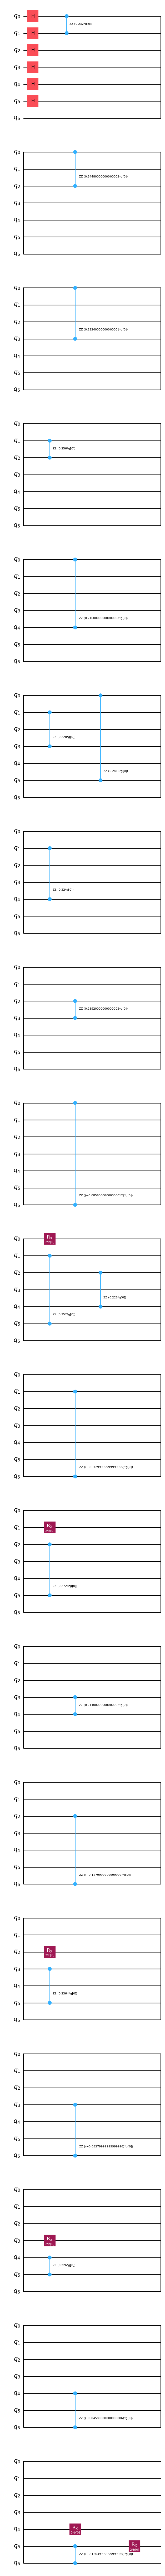

In [5]:
def ising_operator(field, coupling, constant):
    """Sparse Pauli form of H_C on n asset qubits plus the reference qubit."""
    terms = [("I" * (n + 1), constant)]
    for i in range(n):
        for j in range(i + 1, n):
            pauli = ["I"] * (n + 1)
            pauli[i] = "Z"
            pauli[j] = "Z"
            # Qiskit Pauli strings are little-endian: qubit 0 is the rightmost character.
            terms.append(("".join(reversed(pauli)), coupling[i, j]))
        pauli = ["I"] * (n + 1)
        pauli[i] = "Z"
        pauli[n] = "Z"
        terms.append(("".join(reversed(pauli)), field[i]))
    return SparsePauliOp.from_list(terms).simplify()

def qaoa_circuit(field, coupling, depth):
    gammas = ParameterVector("g", depth)
    betas = ParameterVector("b", depth)
    qc = QuantumCircuit(n + 1)
    qc.h(range(n))
    for layer in range(depth):
        for i in range(n):
            for j in range(i + 1, n):
                qc.rzz(gammas[layer] * (2 * coupling[i, j]), i, j)
            qc.rzz(gammas[layer] * (2 * field[i]), i, n)
        for i in range(n):
            qc.rx(2 * betas[layer], i)
    return qc, gammas, betas

def bind_angles(gammas, betas, theta, depth):
    binding = {gammas[k]: float(theta[k]) for k in range(depth)}
    binding.update({betas[k]: float(theta[depth + k]) for k in range(depth)})
    return binding

def distribution_energy(circuit, binding, lam):
    """Sum |amplitude|^2 C(x) over asset bitstrings. Reference excitations are counted apart."""
    state = Statevector(circuit.assign_parameters(binding))
    manual = 0.0
    reference_one = 0.0
    for key, prob in state.probabilities_dict().items():
        bits = key.replace(" ", "")[::-1]
        if bits[n] == "1":
            reference_one += prob
            continue
        x = np.array([int(bits[i]) for i in range(n)], dtype=float)
        manual += prob * cost_direct(x, lam)
    return manual, reference_one

operator = ising_operator(h, J, c)
circuit, gammas, betas = qaoa_circuit(h, J, 1)
print("qubits:", circuit.num_qubits, " parameters:", circuit.num_parameters)
print("gate counts:", dict(circuit.count_ops()))

theta_test = np.array([0.3, 0.4])
binding = bind_angles(gammas, betas, theta_test, 1)
values = [binding[param] for param in circuit.parameters]
expected = float(StatevectorEstimator().run([(circuit, operator, values)]).result()[0].data.evs)
manual, reference_one = distribution_energy(circuit, binding, LAM)
print("estimator <H_C>:", round(expected, 8))
print("sum_x |amp|^2 C(x):", round(manual, 8))
print("probability that the reference qubit is |1>:", reference_one)
assert abs(expected - manual) < 1e-6
assert reference_one < 1e-8

# The observable, without any QAOA gates, reproduces C(x*) on the optimal basis state.
preparation = QuantumCircuit(n + 1)
preparation.x(list(np.flatnonzero(x_star)))
basis_energy = float(StatevectorEstimator().run([(preparation, operator, [])]).result()[0].data.evs)
print("energy of |x*>|0>:", round(basis_energy, 8), " C(x*):", round(cost_direct(x_star, LAM), 8))
assert abs(basis_energy - cost_direct(x_star, LAM)) < 1e-8

circuit.draw("mpl", fold=8)


### How to read the circuit

The drawing starts with six Hadamards. Each following block is one QAOA layer: a run of $\mathrm{RZZ}$ gates, one per edge of the augmented graph (asset pairs, then each asset with the reference), then six $\mathrm{RX}$ gates. Qubit 6 is the reference. It is a target of $\mathrm{RZZ}$ and of nothing else.

The two printed energies agree. That is the check that the gate angles implement the same $H_C$ used to score $C(x)$ classically. The basis-state line is the special case of that check on $x^\star$: the quantum observable returns the penalized portfolio cost, not a rescaled or sign-flipped version of it.

`circuit.parameters` is not used as a bare angle list. Qiskit orders parameters by name, so each angle is written onto its own $\gamma$ or $\beta$ symbol and then read back in the circuit's order.


## 6. Classical parameter optimization with COBYLA

The quantum state depends on the angles. The classical optimizer changes those angles to minimize the expected penalized cost

$$
E(\gamma,\beta)=\langle\psi(\gamma,\beta)|H_C|\psi(\gamma,\beta)\rangle.
$$

`StatevectorEstimator` computes this expectation exactly from the statevector. No shots and no hardware noise enter this step. COBYLA is a local, derivative-free method, and its last proposal is not always the best point it tried. The run stores every evaluated energy and keeps the lowest one. It tries four starts: one smooth guess, and three random starts. In the depth study, a deeper circuit is also started from the previous depth's angles with the new layer set to zero. A zero layer is the identity, so that start reproduces the shallower state.

$E(\gamma,\beta)$ is **not** the portfolio score $f(x)$. It is an average of $C(x)=-f(x)+\lambda(\sum x_i-K)^2$ over every portfolio the state still superposes. A state that has found $x^\star$ but still puts amplitude on other bitstrings has $E$ strictly above $C(x^\star)$.


QAOA expected energy E = 0.020043
same energy from the bitstring distribution = 0.020043
ground-state cost C(x*) = -0.136400
gap E - C(x*) = 0.156443
reference |1> probability: 0.0


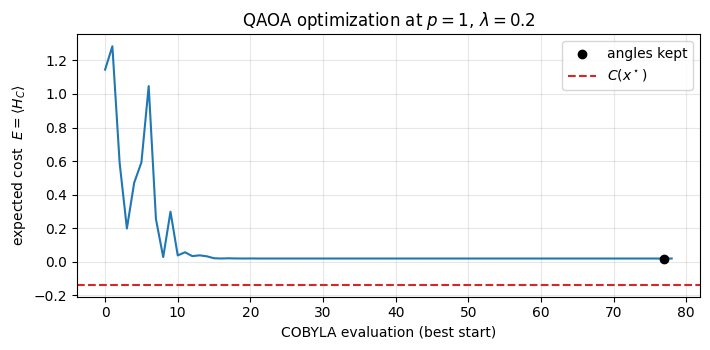

In [6]:
def optimize_qaoa(field, coupling, constant, depth, lam, starts=4, maxiter=100, seed=7, warm_theta=None):
    operator_p = ising_operator(field, coupling, constant)
    qc, gammas_p, betas_p = qaoa_circuit(field, coupling, depth)
    estimator = StatevectorEstimator()
    rng = np.random.default_rng(seed)
    if warm_theta is None:
        initial_points = [np.concatenate([np.linspace(0.3, 0.8, depth), np.linspace(0.6, 0.3, depth)])]
    else:
        initial_points = [np.asarray(warm_theta, dtype=float)]
    for _ in range(starts - 1):
        initial_points.append(np.concatenate([
            rng.uniform(-np.pi, np.pi, depth),
            rng.uniform(0, np.pi, depth),
        ]))

    best_energy = np.inf
    best_theta = None
    best_history = None
    for theta0 in initial_points:
        history = []
        found = [np.inf, None]

        def objective(theta, history=history, found=found):
            binding = bind_angles(gammas_p, betas_p, theta, depth)
            values = [binding[param] for param in qc.parameters]
            energy = float(estimator.run([(qc, operator_p, values)]).result()[0].data.evs)
            history.append(energy)
            if energy < found[0]:
                found[0] = energy
                found[1] = np.array(theta, dtype=float).copy()
            return energy

        minimize(objective, theta0, method="COBYLA", options={"maxiter": maxiter})
        if found[0] < best_energy:
            best_energy = float(found[0])
            best_theta = found[1]
            best_history = list(history)

    return {
        "qc": qc,
        "gammas": gammas_p,
        "betas": betas_p,
        "theta": best_theta,
        "energy": best_energy,
        "history": best_history,
        "depth": depth,
        "lam": lam,
    }

worked = optimize_qaoa(h, J, c, depth=1, lam=LAM)
worked_binding = bind_angles(worked["gammas"], worked["betas"], worked["theta"], 1)
worked_manual, worked_reference = distribution_energy(worked["qc"], worked_binding, LAM)
print(f"QAOA expected energy E = {worked['energy']:.6f}")
print(f"same energy from the bitstring distribution = {worked_manual:.6f}")
print(f"ground-state cost C(x*) = {ground_energy:.6f}")
print(f"gap E - C(x*) = {worked['energy'] - ground_energy:.6f}")
print("reference |1> probability:", worked_reference)
assert abs(worked["energy"] - worked_manual) < 1e-6
assert worked_reference < 1e-8

plt.figure(figsize=(7.2, 3.6))
plt.plot(worked["history"], color="#1f77b4")
kept = int(np.argmin(worked["history"]))
plt.scatter([kept], [worked["history"][kept]], color="black", zorder=3, label="angles kept")
plt.axhline(ground_energy, color="#d62728", linestyle="--", label=r"$C(x^\star)$")
plt.xlabel("COBYLA evaluation (best start)")
plt.ylabel(r"expected cost  $E=\langle H_C\rangle$")
plt.title(r"QAOA optimization at $p=1$, $\lambda=0.2$")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### How to read this

The curve is the penalized energy along the start that produced the best point. COBYLA does not decrease on every evaluation. The energy printed above is the lowest point on that curve, not necessarily the last one. The dashed line is the best possible value of $C$, achieved only by a state concentrated on $x^\star$.

If the blue curve finishes above the dashed line, QAOA has **not** prepared the exact ground state. That is expected at $p=1$. The next section can still recover $x^\star$ from the sampled bitstrings, because "best feasible sample" and "expected energy" answer different questions. The assert checks that the optimized circuit and the classical cost $C(x)$ are still the same function.


## 7. Sampling and portfolio evaluation

Minimizing $E$ tunes the angles. The portfolio is a bitstring. Measure the optimized circuit many times with `StatevectorSampler`. Qiskit returns each outcome as a little-endian string: after reversing it, index $i$ is asset $i$ and the last bit is the reference.

Evaluation rules, in this order:

1. Discard any shot whose reference bit is $1$. There should be none.
2. Discard any shot that does not contain exactly $K$ ones. Those portfolios are illegal, however low $C$ made them look during optimization.
3. Score each remaining shot with the original $f(x)$, **not** with $C(x)$ and not with the Ising energy. The penalty was only a device to bias the circuit.
4. Keep the feasible portfolio with the largest $f$. Its approximation ratio is $f(x_{\mathrm{QAOA}})/f^\star$.

The ratio uses the best feasible sample. It is not $E$, and it is not the average of $f$ over the shots. Those two other numbers are printed beside it so they are not confused.


In [7]:
def sample_portfolios(run, shots=4096):
    depth = run["depth"]
    binding = bind_angles(run["gammas"], run["betas"], run["theta"], depth)
    bound = run["qc"].assign_parameters(binding)
    measured = bound.copy()
    measured.measure_all()
    counts = StatevectorSampler().run([measured], shots=shots).result()[0].data.meas.get_counts()

    reference_bad = 0
    feasible_shots = 0
    feasible_f_sum = 0.0
    best = None
    by_count = []
    for key, count in counts.items():
        bits = key.replace(" ", "")[::-1]
        if bits[n] == "1":
            reference_bad += count
            continue
        x = np.array([int(bits[i]) for i in range(n)], dtype=int)
        value = portfolio_value(x)
        by_count.append((x, count, int(x.sum()), value))
        if int(x.sum()) == K:
            feasible_shots += count
            feasible_f_sum += value * count
            if best is None or value > best[3]:
                best = (x.copy(), count, K, value)
    by_count.sort(key=lambda row: row[1], reverse=True)

    exact_feasible = 0.0
    exact_optimal = 0.0
    state = Statevector(bound)
    for key, prob in state.probabilities_dict().items():
        bits = key.replace(" ", "")[::-1]
        if bits[n] == "1":
            continue
        x = np.array([int(bits[i]) for i in range(n)], dtype=int)
        if int(x.sum()) == K:
            exact_feasible += prob
        if np.array_equal(x, x_star.astype(int)):
            exact_optimal += prob

    return {
        "best": best,
        "by_count": by_count,
        "sampled_feasibility": feasible_shots / shots,
        "mean_feasible_f": None if feasible_shots == 0 else feasible_f_sum / feasible_shots,
        "reference_bad": reference_bad,
        "exact_feasibility": exact_feasible,
        "exact_optimal_probability": exact_optimal,
        "shots": shots,
    }

SHOTS = 4096
worked_samples = sample_portfolios(worked, shots=SHOTS)
best_x, best_count, _, best_f = worked_samples["best"]
worked_ratio = best_f / f_star

print("Most frequent measured bitstrings (assets, count, number held, f):")
for x, count, held, value in worked_samples["by_count"][:5]:
    print(f"  {x.tolist()}   count={count:5d}   held={held}   f={value: .4f}")
print("reference shots in |1>:", worked_samples["reference_bad"])
print("sampled feasibility rate:", round(worked_samples["sampled_feasibility"], 4))
print("exact feasibility probability:", round(worked_samples["exact_feasibility"], 4))
print("exact probability of x*:", round(worked_samples["exact_optimal_probability"], 4))
print("QAOA expected energy E:", round(worked["energy"], 6))
print("best feasible sample: assets", np.flatnonzero(best_x).tolist(), " f =", round(best_f, 6))
print("brute-force optimum:  assets", np.flatnonzero(x_star).tolist(), " f* =", round(f_star, 6))
print("approximation ratio of the best feasible sample:", round(worked_ratio, 6))
print("mean f of feasible shots / f*:", round(worked_samples["mean_feasible_f"] / f_star, 6))
assert worked_samples["reference_bad"] == 0
assert abs(best_x.sum() - K) < 1e-12


Most frequent measured bitstrings (assets, count, number held, f):
  [1, 1, 1, 0, 0, 0]   count=  150   held=3   f= 0.0334
  [1, 0, 0, 1, 0, 1]   count=  146   held=3   f= 0.0600
  [0, 1, 0, 1, 1, 0]   count=  146   held=3   f= 0.1364
  [1, 0, 1, 0, 1, 0]   count=  144   held=3   f= 0.0646
  [1, 1, 0, 1, 0, 0]   count=  144   held=3   f= 0.1086
reference shots in |1>: 0
sampled feasibility rate: 0.6453
exact feasibility probability: 0.6484
exact probability of x*: 0.0348
QAOA expected energy E: 0.020043
best feasible sample: assets [1, 3, 4]  f = 0.1364
brute-force optimum:  assets [1, 3, 4]  f* = 0.1364
approximation ratio of the best feasible sample: 1.0
mean f of feasible shots / f*: 0.466984


### How to read this

The count table is the raw measurement. A row with `held` different from 3 is an illegal portfolio and is ignored when choosing the answer, even if it appears often.

`E` averages the penalized cost, including illegal states. The approximation ratio divides two values of $f$. Those numbers live on different scales and should not be set equal to each other.

On six assets, 4096 shots usually see every bitstring that has more than a fraction of a percent of the probability. The best feasible sample can therefore be optimal even when $E$ is still well above $C(x^\star)$ and even when the single most frequent bitstring is a different portfolio. Section 8 plots that saturation against depth, and also plots the average feasible score, which still has room to move.


## 8. Approximation ratio and the two experiments

Both experiments reuse the same coefficients, the same circuit, and the same COBYLA routine. Only $p$ or $\lambda$ changes.

**Experiment A.** $\lambda$ stays at the worked-example value. The depth takes the values $p=1,2,3$. Each deeper circuit is warm-started from the previous angles plus a new layer at angle $0$, and random COBYLA starts are still allowed to beat that seed. For each depth we record:

- the best feasible sample's approximation ratio $f/f^\star$,
- the shot-averaged feasible score, also divided by $f^\star$.

The first is the number the challenge asks for. The second is there because, on a 6-asset instance, the best sample often hits $x^\star$ as soon as that bitstring has a small but nonzero probability. A flat best-sample curve then means "the optimum was present in the sample," not "depth did nothing."

**Experiment B.** The depth stays at $p=1$, and $\lambda$ varies, including values below $\lambda_{\min}$. The feasibility rate is the fraction of the measured distribution on bitstrings with exactly $K$ ones. The same plot marks whether the **classical** minimizer of $C$ is legal. A weak penalty can make an illegal portfolio the true ground state of $H_C$. QAOA is then asked to find an illegal answer, and the samples follow.


optimizing p = 1 ...


optimizing p = 2 ...


optimizing p = 3 ...



Depth study at lambda = 0.2
  p           E      best f   best ratio   mean ratio   P(legal)  assets
  1      0.0200      0.1364        1.000        0.460      0.648  [1, 3, 4]
  2      0.0044      0.1364        1.000        0.464      0.725  [1, 3, 4]
  3     -0.0238      0.1364        1.000        0.478      0.827  [1, 3, 4]


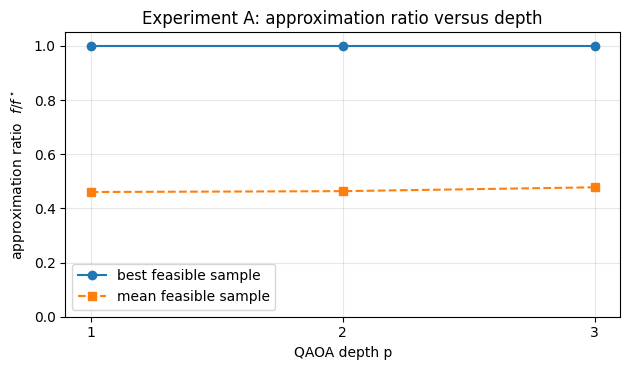

In [8]:
depth_rows = []
previous_theta = None
for depth in (1, 2, 3):
    print(f"optimizing p = {depth} ...")
    warm = None
    if previous_theta is not None:
        p_prev = depth - 1
        # [gammas..., 0, betas..., 0]: the new layer is the identity.
        warm = np.concatenate([
            previous_theta[:p_prev], [0.0],
            previous_theta[p_prev:], [0.0],
        ])
    run = optimize_qaoa(h, J, c, depth=depth, lam=LAM, warm_theta=warm)
    previous_theta = run["theta"]
    samples = sample_portfolios(run, shots=SHOTS)
    best_value = None if samples["best"] is None else samples["best"][3]
    depth_rows.append({
        "p": depth,
        "energy": run["energy"],
        "best_f": best_value,
        "best_ratio": None if best_value is None else best_value / f_star,
        "mean_ratio": None if samples["mean_feasible_f"] is None else samples["mean_feasible_f"] / f_star,
        "feasibility": samples["exact_feasibility"],
        "assets": None if samples["best"] is None else np.flatnonzero(samples["best"][0]).tolist(),
    })

print("\nDepth study at lambda =", LAM)
print(f"{'p':>3}  {'E':>10}  {'best f':>10}  {'best ratio':>11}  {'mean ratio':>11}  {'P(legal)':>9}  assets")
for row in depth_rows:
    print(f"{row['p']:3d}  {row['energy']:10.4f}  {row['best_f']:10.4f}  {row['best_ratio']:11.3f}  "
          f"{row['mean_ratio']:11.3f}  {row['feasibility']:9.3f}  {row['assets']}")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ps = [row["p"] for row in depth_rows]
ax.plot(ps, [row["best_ratio"] for row in depth_rows], "o-", color="#1f77b4", label="best feasible sample")
ax.plot(ps, [row["mean_ratio"] for row in depth_rows], "s--", color="#ff7f0e", label="mean feasible sample")
ax.set_xticks(ps)
ax.set_ylim(0, 1.05)
ax.set_xlabel("QAOA depth p")
ax.set_ylabel(r"approximation ratio  $f / f^\star$")
ax.set_title(r"Experiment A: approximation ratio versus depth")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


optimizing lambda = 0.0 ...


optimizing lambda = 0.005 ...


optimizing lambda = 0.01 ...


optimizing lambda = 0.02 ...


optimizing lambda = 0.05 ...


optimizing lambda = 0.1 ...


optimizing lambda = 0.2 ...


optimizing lambda = 0.5 ...


optimizing lambda = 1.0 ...



Penalty study at p = 1
  lambda   P_QAOA(legal)  shots(legal)    C ground legal
   0.000           0.322         0.323             False
   0.005           0.351         0.358             False
   0.010           0.376         0.378              True
   0.020           0.414         0.410              True
   0.050           0.515         0.518              True
   0.100           0.601         0.599              True
   0.200           0.648         0.645              True
   0.500           0.667         0.672              True
   1.000           0.670         0.660              True


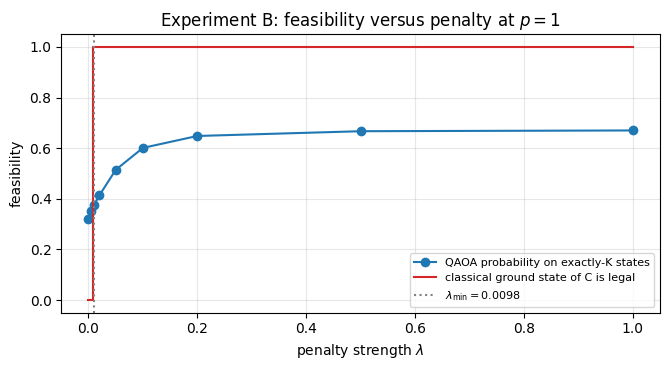

In [9]:
lambda_grid = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
lambda_rows = []
for lam in lambda_grid:
    print(f"optimizing lambda = {lam} ...")
    a_l, b_l, c0_l, h_l, J_l, c_l = ising_from_portfolio(lam)
    run = optimize_qaoa(h_l, J_l, c_l, depth=1, lam=lam)
    samples = sample_portfolios(run, shots=SHOTS)
    ground_x = None
    ground_c = np.inf
    for bits in product([0, 1], repeat=n):
        x = np.array(bits, dtype=float)
        value = cost_direct(x, lam)
        if value < ground_c - 1e-12:
            ground_c = value
            ground_x = x
    lambda_rows.append({
        "lam": lam,
        "qaoa_feasibility": samples["exact_feasibility"],
        "sampled_feasibility": samples["sampled_feasibility"],
        "ground_feasible": int(ground_x.sum()) == K,
        "energy": run["energy"],
        "ground_c": ground_c,
    })

print("\nPenalty study at p = 1")
print(f"{'lambda':>8}  {'P_QAOA(legal)':>14}  {'shots(legal)':>12}  {'C ground legal':>16}")
for row in lambda_rows:
    print(f"{row['lam']:8.3f}  {row['qaoa_feasibility']:14.3f}  {row['sampled_feasibility']:12.3f}  "
          f"{str(row['ground_feasible']):>16}")

fig, ax = plt.subplots(figsize=(6.8, 3.8))
lams = [row["lam"] for row in lambda_rows]
ax.plot(lams, [row["qaoa_feasibility"] for row in lambda_rows], "o-", color="#1f77b4",
        label="QAOA probability on exactly-K states")
ax.step(lams, [1.0 if row["ground_feasible"] else 0.0 for row in lambda_rows],
        where="mid", color="#d62728", label="classical ground state of C is legal")
ax.axvline(lambda_min, color="gray", linestyle=":", label=fr"$\lambda_{{\min}}={lambda_min:.4f}$")
ax.set_xlabel(r"penalty strength $\lambda$")
ax.set_ylabel("feasibility")
ax.set_ylim(-0.05, 1.05)
ax.set_title(r"Experiment B: feasibility versus penalty at $p=1$")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### How to read the two plots

**Depth plot.** The blue markers are the challenge metric: best legal portfolio found in the shots, divided by the brute-force $f^\star$. A value of $1$ means that sample **is** an optimal portfolio. On this 6-asset instance that can happen as soon as $x^\star$ has a few percent of the probability, so the blue curve can sit at $1$ for every $p$ tested. The orange markers average $f$ over legal shots only. They stay below $1$ while amplitude remains on second-best legal portfolios. Read the energy column in the table the same way: it is $\langle H_C\rangle$, and it can fall toward $C(x^\star)$ without the blue ratio moving.

**Penalty plot.** Left of $\lambda_{\min}$, the red step is $0$: the bitstring of lowest $C$ is illegal. QAOA is minimizing a cost whose preferred answer violates the budget, so many samples are illegal. Right of $\lambda_{\min}$, the classical ground state is the legal optimum, but a $p=1$ state is only an approximation to that ground state. Illegal bitstrings remain in the superposition, so the blue curve rises more slowly than the red step and need not reach $1$. Raising $\lambda$ further inflates every illegal cost, which is why the sampled mass shifts toward exactly-$K$ states. If $\lambda$ is enormous compared with the gaps in $f$, those gaps become a small perturbation on a pure penalty Hamiltonian and the optimizer has to resolve a weaker portfolio signal. $\lambda=0.2$, about twenty times $\lambda_{\min}$ for this instance, is the compromise used above.

The shot column should sit close to the exact probability. A large disagreement would mean the sampler and the statevector are being read differently.


In [10]:
# Final numbers use the deepest run in the depth table, which shares lambda with the worked example.
chosen = max(depth_rows, key=lambda row: (row["best_ratio"], row["p"]))
print("Brute-force optimal portfolio: assets", np.flatnonzero(x_star).tolist())
print("  f* =", round(f_star, 6))
print(f"QAOA portfolio reported from p = {chosen['p']}, lambda = {LAM}: assets", chosen["assets"])
print("  f =", round(chosen["best_f"], 6))
print("  approximation ratio =", round(chosen["best_ratio"], 6))
print("  QAOA expected energy at that depth =", round(chosen["energy"], 6))
print("  classical ground cost C(x*) =", round(ground_energy, 6))
print("Simulator: StatevectorEstimator and StatevectorSampler, 7 qubits, no device noise.")
print("No quantum advantage is claimed. Brute force over 20 feasible portfolios is exact here.")


Brute-force optimal portfolio: assets [1, 3, 4]
  f* = 0.1364
QAOA portfolio reported from p = 3, lambda = 0.2: assets [1, 3, 4]
  f = 0.1364
  approximation ratio = 1.0
  QAOA expected energy at that depth = -0.023792
  classical ground cost C(x*) = -0.1364
Simulator: StatevectorEstimator and StatevectorSampler, 7 qubits, no device noise.
No quantum advantage is claimed. Brute force over 20 feasible portfolios is exact here.


### Workflow in one pass

1. Score $f(x)=\mu^\top x-q\,x^\top\sigma x$ and keep the best of the $\binom{6}{3}$ legal portfolios. That is $f^\star$.
2. Minimize $C(x)=-f(x)+\lambda(\sum_i x_i-K)^2$ instead, and expand $C$ into QUBO coefficients $a_i$, $b_{ij}$.
3. Replace $x_i=(1-Z_i)/2$ to get $H_C=c+\sum_i h_i Z_i+\sum_{i<j}J_{ij}Z_i Z_j$.
4. Pin a reference spin at $Z_r=+1$ and rewrite every field as an edge, $w_{ir}=2h_i$, $w_{ij}=2J_{ij}$. Negative $w_{ir}$ is allowed. This is generalised weighted Max-Cut.
5. Build one QAOA layer as Hadamards (assets only), $\mathrm{RZZ}(\gamma w)$ on every edge, and $\mathrm{RX}(2\beta)$ on the assets. Repeat it $p$ times. The reference qubit stays in $|0\rangle$.
6. Let COBYLA minimize the exact expectation of that same $H_C$.
7. Sample bitstrings, reject those that do not hold $K$ assets, and score the survivors with $f$. The ratio of the best survivor to $f^\star$ is the approximation ratio. The expectation $E$ is a different number: it still averages the penalty.
